In [4]:
# ============================================
# 1. IMPORT LIBRARIES AND LOAD TESS DATASET
# ============================================

import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

import torch
import torch.nn as nn

# Identify project root
current_dir = Path.cwd()

if current_dir.name == "notebooks":
    project_root = current_dir.parent
else:
    project_root = current_dir

# Dataset paths
tess_path = project_root / "data" / "processed" / "tess_clean.csv"
kepler_path = project_root / "data" / "processed" / "kepler_clean.csv"

# Load datasets
tess = pd.read_csv(tess_path)
kepler = pd.read_csv(kepler_path)

print("DATASETS LOADED SUCCESSFULLY")
print("=" * 50)

print("TESS Shape:", tess.shape)
print("Kepler Shape:", kepler.shape)

print("\nTESS Columns:", len(tess.columns))
print("Kepler Columns:", len(kepler.columns))

print("\nTESS Dataset Preview:")
display(tess.head())

print("\nAvailable model artifacts:")
model_dir = project_root / "models"

for file in model_dir.iterdir():
    if file.is_file():
        print(file.name)

DATASETS LOADED SUCCESSFULLY
TESS Shape: (8175, 51)
Kepler Shape: (9564, 114)

TESS Columns: 51
Kepler Columns: 114

TESS Dataset Preview:


,rowid,toi,toipfx,tid,ctoi_alias,pl_pnum,tfopwg_disp,rastr,ra,decstr,...,st_tefferr1,st_tefferr2,st_logg,st_loggerr1,st_loggerr2,st_rad,st_raderr1,st_raderr2,toi_created,rowupdate
0,1,1000.01,1000,50365310,5.036531e+07,1,FP,07h29m25.85s,112.357708,-12d41m45.46s,...,264.7,-264.7,4.19,0.07,-0.07,2.16986,0.072573,-0.072573,2019-07-24 15:58:33,2024-09-09 10:08:01
1,2,1001.01,1001,88863718,8.886372e+07,1,PC,08h10m19.31s,122.580465,-05d30m49.87s,...,126.4,-126.4,4.03,0.09,-0.09,2.01000,0.090000,-0.090000,2019-07-24 15:58:33,2023-04-03 14:31:04
2,3,1002.01,1002,124709665,1.247097e+08,1,FP,06h58m54.47s,104.726966,-10d34m49.64s,...,124.0,-124.0,NaN,NaN,NaN,5.73000,NaN,NaN,2019-07-24 15:58:33,2022-07-11 16:02:02
3,4,1003.01,1003,106997505,1.069975e+08,1,FP,07h22m14.39s,110.559945,-25d12m25.26s,...,567.0,-567.0,4.15,1.64,-1.64,NaN,NaN,NaN,2019-07-24 15:58:33,2022-02-23 10:10:02
4,5,1004.01,1004,238597883,2.385979e+08,1,FP,08h08m42.77s,122.178195,-48d48m10.12s,...,171.1,-171.1,4.14,0.07,-0.07,2.15000,0.060000,-0.060000,2019-07-24 15:58:33,2024-09-09 10:08:01



Available model artifacts:
dl_feature_names.json
dl_imputer.pkl
dl_label_encoder.pkl
dl_scaler.pkl
exodetect_catboost_final.pkl
exodetect_weighted_mlp.pth
kepler_preprocessing_pipeline.pkl
weighted_mlp_results.json


In [5]:
# ============================================
# 2. DATASET FEATURE AND TARGET INSPECTION
# ============================================

print("TESS DATASET COLUMNS")
print("=" * 60)

for i, col in enumerate(tess.columns, 1):
    print(f"{i:2}. {col}")

print("\nKEPLER DATASET COLUMNS")
print("=" * 60)

for i, col in enumerate(kepler.columns, 1):
    print(f"{i:2}. {col}")

# Target distributions
print("\nTESS TARGET DISTRIBUTION")
print("=" * 60)

print(tess["tfopwg_disp"].value_counts(dropna=False))

print("\nKEPLER TARGET DISTRIBUTION")
print("=" * 60)

print(kepler["koi_disposition"].value_counts(dropna=False))

# Load Kepler feature names used by the MLP
with open(model_dir / "dl_feature_names.json", "r") as file:
    dl_feature_names = json.load(file)

print("\nMLP EXPECTED FEATURES")
print("=" * 60)

for i, feature in enumerate(dl_feature_names, 1):
    print(f"{i:2}. {feature}")

# Inspect CatBoost model
catboost_model = joblib.load(
    model_dir / "exodetect_catboost_final.pkl"
)

print("\nCATBOOST MODEL INFORMATION")
print("=" * 60)

print("Model type:", type(catboost_model))

if hasattr(catboost_model, "feature_names_"):
    print("Number of CatBoost features:",
          len(catboost_model.feature_names_))

    print("CatBoost features:")
    print(catboost_model.feature_names_)

TESS DATASET COLUMNS
 1. rowid
 2. toi
 3. toipfx
 4. tid
 5. ctoi_alias
 6. pl_pnum
 7. tfopwg_disp
 8. rastr
 9. ra
10. decstr
11. dec
12. st_pmra
13. st_pmraerr1
14. st_pmraerr2
15. st_pmdec
16. st_pmdecerr1
17. st_pmdecerr2
18. pl_tranmid
19. pl_tranmiderr1
20. pl_tranmiderr2
21. pl_orbper
22. pl_orbpererr1
23. pl_orbpererr2
24. pl_trandurh
25. pl_trandurherr1
26. pl_trandurherr2
27. pl_trandep
28. pl_trandeperr1
29. pl_trandeperr2
30. pl_rade
31. pl_radeerr1
32. pl_radeerr2
33. pl_insol
34. pl_eqt
35. st_tmag
36. st_tmagerr1
37. st_tmagerr2
38. st_dist
39. st_disterr1
40. st_disterr2
41. st_teff
42. st_tefferr1
43. st_tefferr2
44. st_logg
45. st_loggerr1
46. st_loggerr2
47. st_rad
48. st_raderr1
49. st_raderr2
50. toi_created
51. rowupdate

KEPLER DATASET COLUMNS
 1. rowid
 2. kepid
 3. kepoi_name
 4. kepler_name
 5. koi_disposition
 6. koi_pdisposition
 7. koi_score
 8. koi_fpflag_nt
 9. koi_fpflag_ss
10. koi_fpflag_co
11. koi_fpflag_ec
12. koi_comment
13. koi_period
14. koi_peri

In [6]:
# ============================================
# 3. INSPECT SAVED MODEL ARTIFACTS
# ============================================

# Inspect CatBoost artifact
print("CATBOOST ARTIFACT")
print("=" * 60)

print("Artifact type:", type(catboost_model))

if isinstance(catboost_model, dict):

    print("\nDictionary keys:")

    for key, value in catboost_model.items():

        print(f"\nKey: {key}")
        print("Value type:", type(value))

        if isinstance(value, (list, tuple, np.ndarray)):
            print("Length/Shape:", np.shape(value))

        elif isinstance(value, dict):
            print("Nested keys:", list(value.keys()))

        else:
            print("Value:", str(value)[:300])

# Inspect preprocessing pipeline
print("\n\nKEPLER PREPROCESSING PIPELINE")
print("=" * 60)

pipeline = joblib.load(
    model_dir / "kepler_preprocessing_pipeline.pkl"
)

print("Pipeline type:", type(pipeline))

if hasattr(pipeline, "named_steps"):
    print("Pipeline steps:", pipeline.named_steps.keys())

# Inspect DL preprocessing artifacts
print("\n\nDEEP LEARNING PREPROCESSING")
print("=" * 60)

dl_imputer = joblib.load(model_dir / "dl_imputer.pkl")
dl_scaler = joblib.load(model_dir / "dl_scaler.pkl")
dl_label_encoder = joblib.load(model_dir / "dl_label_encoder.pkl")

print("Imputer:", type(dl_imputer))
print("Scaler:", type(dl_scaler))
print("Label encoder:", type(dl_label_encoder))

print("\nExpected MLP feature count:", len(dl_feature_names))
print("Imputer feature count:", len(dl_imputer.statistics_))
print("Scaler feature count:", len(dl_scaler.mean_))

print("\nMLP class mapping:")

for index, label in enumerate(dl_label_encoder.classes_):
    print(index, ":", label)

CATBOOST ARTIFACT
Artifact type: <class 'dict'>

Dictionary keys:

Key: pipeline
Value type: <class 'sklearn.pipeline.Pipeline'>
Value: Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('classifier',
                 CatBoostClassifier(depth=8, iterations=500, l2_leaf_reg=5, learning_rate=0.05, loss_function='MultiClass', random_seed=42, verbose=0))])

Key: feature_names
Value type: <class 'list'>
Length/Shape: (31,)

Key: target_classes
Value type: <class 'list'>
Length/Shape: (3,)

Key: model_name
Value type: <class 'str'>
Value: CatBoost

Key: test_macro_f1
Value type: <class 'float'>
Value: 0.7526988234449726


KEPLER PREPROCESSING PIPELINE
Pipeline type: <class 'sklearn.pipeline.Pipeline'>
Pipeline steps: dict_keys(['imputer', 'scaler'])


DEEP LEARNING PREPROCESSING
Imputer: <class 'sklearn.impute._base.SimpleImputer'>
Scaler: <class 'sklearn.preprocessing._data.StandardScaler'>
Label encoder: <class 'sklearn.preprocessing._label.LabelEncoder'>

Expe

In [7]:
# ============================================
# 4. KEPLER-TESS FEATURE COMPATIBILITY
# ============================================

# Extract CatBoost artifact components
catboost_pipeline = catboost_model["pipeline"]
catboost_features = catboost_model["feature_names"]
catboost_classes = catboost_model["target_classes"]

# Verify both models use the same features
print("CATBOOST EXPECTED FEATURES")
print("=" * 60)

for i, feature in enumerate(catboost_features, 1):
    print(f"{i:2}. {feature}")

print("\nCATBOOST TARGET CLASSES:")
print(catboost_classes)

print("\nFEATURE CONSISTENCY CHECK")
print("=" * 60)

print(
    "CatBoost and MLP feature lists identical:",
    catboost_features == dl_feature_names
)

# Initial candidate feature mapping
candidate_mapping = {
    "koi_period": "pl_orbper",
    "koi_time0bk": "pl_tranmid",
    "koi_duration": "pl_trandurh",
    "koi_prad": "pl_rade",
    "koi_insol": "pl_insol",
    "koi_teq": "pl_eqt",
    "koi_steff": "st_teff",
    "koi_slogg": "st_logg",
    "koi_srad": "st_rad"
}

# Display mapping availability
mapping_results = []

for kepler_feature, tess_feature in candidate_mapping.items():

    mapping_results.append({
        "Kepler Feature": kepler_feature,
        "TESS Feature": tess_feature,
        "Kepler Available": kepler_feature in kepler.columns,
        "TESS Available": tess_feature in tess.columns
    })

mapping_df = pd.DataFrame(mapping_results)

display(mapping_df)

print("\nFEATURE AVAILABILITY SUMMARY")
print("=" * 60)

print(
    "Candidate mappings:",
    len(mapping_df)
)

print(
    "Available in both datasets:",
    (
        mapping_df["Kepler Available"]
        & mapping_df["TESS Available"]
    ).sum()
)

# Check missing values in candidate TESS features
print("\nTESS MISSING VALUES IN CANDIDATE FEATURES")
print("=" * 60)

for feature in candidate_mapping.values():

    if feature in tess.columns:

        missing = tess[feature].isna().sum()

        print(
            f"{feature:15} "
            f"Missing: {missing:5} "
            f"({missing / len(tess) * 100:.2f}%)"
        )

CATBOOST EXPECTED FEATURES
 1. koi_period
 2. koi_time0bk
 3. koi_time0
 4. koi_impact
 5. koi_duration
 6. koi_depth
 7. koi_ror
 8. koi_srho
 9. koi_prad
10. koi_sma
11. koi_incl
12. koi_teq
13. koi_insol
14. koi_dor
15. koi_ldm_coeff2
16. koi_ldm_coeff1
17. koi_model_snr
18. koi_count
19. koi_steff
20. koi_slogg
21. koi_smet
22. koi_srad
23. koi_smass
24. koi_kepmag
25. koi_gmag
26. koi_rmag
27. koi_imag
28. koi_zmag
29. koi_jmag
30. koi_hmag
31. koi_kmag

CATBOOST TARGET CLASSES:
['CANDIDATE', 'CONFIRMED', 'FALSE POSITIVE']

FEATURE CONSISTENCY CHECK
CatBoost and MLP feature lists identical: True


,Kepler Feature,TESS Feature,Kepler Available,TESS Available
0,koi_period,pl_orbper,True,True
1,koi_time0bk,pl_tranmid,True,True
2,koi_duration,pl_trandurh,True,True
3,koi_prad,pl_rade,True,True
4,koi_insol,pl_insol,True,True
5,koi_teq,pl_eqt,True,True
6,koi_steff,st_teff,True,True
7,koi_slogg,st_logg,True,True
8,koi_srad,st_rad,True,True



FEATURE AVAILABILITY SUMMARY
Candidate mappings: 9
Available in both datasets: 9

TESS MISSING VALUES IN CANDIDATE FEATURES
pl_orbper       Missing:   109 (1.33%)
pl_tranmid      Missing:     0 (0.00%)
pl_trandurh     Missing:     4 (0.05%)
pl_rade         Missing:   519 (6.35%)
pl_insol        Missing:   185 (2.26%)
pl_eqt          Missing:   312 (3.82%)
st_teff         Missing:   175 (2.14%)
st_logg         Missing:   902 (11.03%)
st_rad          Missing:   631 (7.72%)


In [8]:
# ============================================
# 5. FINAL KEPLER-TESS FEATURE MAPPING
# ============================================

feature_mapping = {
    "koi_period": "pl_orbper",
    "koi_time0bk": "pl_tranmid",
    "koi_duration": "pl_trandurh",
    "koi_depth": "pl_trandep",
    "koi_prad": "pl_rade",
    "koi_insol": "pl_insol",
    "koi_teq": "pl_eqt",
    "koi_steff": "st_teff",
    "koi_slogg": "st_logg",
    "koi_srad": "st_rad"
}

# Verify all mapped columns exist
for kepler_feature, tess_feature in feature_mapping.items():

    assert kepler_feature in kepler.columns, (
        f"Missing Kepler feature: {kepler_feature}"
    )

    assert tess_feature in tess.columns, (
        f"Missing TESS feature: {tess_feature}"
    )

print("All mapped features are available!")
print("Number of shared features:", len(feature_mapping))


# Create mapping table
mapping_table = pd.DataFrame([
    {
        "Kepler Feature": k,
        "TESS Feature": t
    }
    for k, t in feature_mapping.items()
])

display(mapping_table)


# Check missing values
print("\nMISSING VALUES IN MAPPED FEATURES")
print("=" * 60)

for feature in feature_mapping.values():

    missing = tess[feature].isna().sum()

    print(
        f"{feature:15} "
        f"{missing:5} missing "
        f"({missing / len(tess) * 100:.2f}%)"
    )


# Check TESS target availability
print("\nTESS DISPOSITION COUNTS")
print("=" * 60)

print(tess["tfopwg_disp"].value_counts(dropna=False))


# Define conservative target mapping
target_mapping = {
    "PC": "CANDIDATE",
    "CP": "CONFIRMED",
    "FP": "FALSE POSITIVE"
}

print("\nTARGET MAPPING")
print("=" * 60)

for tess_label, kepler_label in target_mapping.items():
    print(f"{tess_label} -> {kepler_label}")

All mapped features are available!
Number of shared features: 10


,Kepler Feature,TESS Feature
0,koi_period,pl_orbper
1,koi_time0bk,pl_tranmid
2,koi_duration,pl_trandurh
3,koi_depth,pl_trandep
4,koi_prad,pl_rade
5,koi_insol,pl_insol
6,koi_teq,pl_eqt
7,koi_steff,st_teff
8,koi_slogg,st_logg
9,koi_srad,st_rad



MISSING VALUES IN MAPPED FEATURES
pl_orbper         109 missing (1.33%)
pl_tranmid          0 missing (0.00%)
pl_trandurh         4 missing (0.05%)
pl_trandep          0 missing (0.00%)
pl_rade           519 missing (6.35%)
pl_insol          185 missing (2.26%)
pl_eqt            312 missing (3.82%)
st_teff           175 missing (2.14%)
st_logg           902 missing (11.03%)
st_rad            631 missing (7.72%)

TESS DISPOSITION COUNTS
tfopwg_disp
PC     4832
FP     1319
CP      821
KP      609
APC     494
FA       98
NaN       2
Name: count, dtype: int64

TARGET MAPPING
PC -> CANDIDATE
CP -> CONFIRMED
FP -> FALSE POSITIVE


In [9]:
# Shared feature mapping (excluding transit epoch)

feature_mapping = {
    "koi_period": "pl_orbper",
    "koi_duration": "pl_trandurh",
    "koi_depth": "pl_trandep",
    "koi_prad": "pl_rade",
    "koi_insol": "pl_insol",
    "koi_teq": "pl_eqt",
    "koi_steff": "st_teff",
    "koi_slogg": "st_logg",
    "koi_srad": "st_rad"
}

shared_features = list(feature_mapping.keys())
tess_features = list(feature_mapping.values())

print("NUMBER OF SHARED FEATURES:", len(shared_features))

print("\nFEATURE MAPPING")
print("=" * 65)

for kepler_feature, tess_feature in feature_mapping.items():
    print(f"{kepler_feature:<20} -> {tess_feature}")

# Create aligned datasets with identical feature names

kepler_shared = kepler[shared_features].copy()

tess_shared = tess[tess_features].copy()
tess_shared.columns = shared_features

print("\nKEPLER SHARED DATA SHAPE:", kepler_shared.shape)
print("TESS SHARED DATA SHAPE:", tess_shared.shape)

print("\nKEPLER FEATURE STATISTICS")
display(kepler_shared.describe().T)

print("\nTESS FEATURE STATISTICS")
display(tess_shared.describe().T)

NUMBER OF SHARED FEATURES: 9

FEATURE MAPPING
koi_period           -> pl_orbper
koi_duration         -> pl_trandurh
koi_depth            -> pl_trandep
koi_prad             -> pl_rade
koi_insol            -> pl_insol
koi_teq              -> pl_eqt
koi_steff            -> st_teff
koi_slogg            -> st_logg
koi_srad             -> st_rad

KEPLER SHARED DATA SHAPE: (9564, 9)
TESS SHARED DATA SHAPE: (8175, 9)

KEPLER FEATURE STATISTICS


,count,mean,std,min,25%,50%,75%,max
koi_period,9564.0,75.671358,1334.744046,0.241843,2.733684,9.752831,40.715178,1.299958e+05
koi_duration,9564.0,5.621606,6.471554,0.052000,2.437750,3.792600,6.276500,1.385400e+02
koi_depth,9201.0,23791.335898,82242.683149,0.000000,159.900000,421.100000,1473.400000,1.541400e+06
koi_prad,9201.0,102.891778,3077.639126,0.080000,1.400000,2.390000,14.930000,2.003460e+05
koi_insol,9243.0,7745.737023,159204.665200,0.000000,20.150000,141.600000,870.290000,1.094755e+07
koi_teq,9201.0,1085.385828,856.351161,25.000000,539.000000,878.000000,1379.000000,1.466700e+04
koi_steff,9201.0,5706.823280,796.857947,2661.000000,5310.000000,5767.000000,6112.000000,1.589600e+04
koi_slogg,9201.0,4.310157,0.432606,0.047000,4.218000,4.438000,4.543000,5.364000e+00
koi_srad,9201.0,1.728712,6.127185,0.109000,0.829000,1.000000,1.345000,2.299080e+02



TESS FEATURE STATISTICS


,count,mean,std,min,25%,50%,75%,max
koi_period,8066.0,17.723236,97.344199,0.152076,2.519329,4.152482,8.204959,1837.889731
koi_duration,8171.0,3.089388,1.893665,0.101000,1.848845,2.756000,3.851470,30.015619
koi_depth,8175.0,8216.099937,16986.948387,24.583493,1450.912515,4735.000000,10294.500000,767910.313098
koi_prad,7656.0,10.291567,8.411719,0.552507,4.547985,10.486100,13.941000,297.111726
koi_insol,7990.0,2352.489573,11040.346238,0.000342,88.100203,378.485000,1225.866593,280833.000000
koi_teq,7863.0,1298.941519,698.796525,37.000000,824.000000,1193.000000,1607.177074,6413.000000
koi_steff,8000.0,5788.016249,1462.777081,2808.000000,5215.000000,5799.350000,6294.000000,50000.000000
koi_slogg,7273.0,4.304721,0.303534,0.100000,4.120000,4.330000,4.500000,5.960650
koi_srad,7544.0,1.400522,1.566177,0.114827,0.890000,1.236045,1.660000,102.030000


In [10]:
# Feature quality and outlier investigation

for name, df in [("KEPLER", kepler_shared), ("TESS", tess_shared)]:

    print(f"\n{'=' * 75}")
    print(f"{name} FEATURE QUALITY CHECK")
    print("=" * 75)

    for col in shared_features:

        series = df[col]

        q1 = series.quantile(0.25)
        q3 = series.quantile(0.75)
        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        outliers = ((series < lower) | (series > upper)).sum()

        print(
            f"{col:<15} | "
            f"Missing: {series.isna().sum():<5} | "
            f"Zeros: {(series == 0).sum():<5} | "
            f"Negative: {(series < 0).sum():<5} | "
            f"IQR outliers: {outliers}"
        )


KEPLER FEATURE QUALITY CHECK
koi_period      | Missing: 0     | Zeros: 0     | Negative: 0     | IQR outliers: 1567
koi_duration    | Missing: 0     | Zeros: 0     | Negative: 0     | IQR outliers: 869
koi_depth       | Missing: 363   | Zeros: 1     | Negative: 0     | IQR outliers: 1798
koi_prad        | Missing: 363   | Zeros: 0     | Negative: 0     | IQR outliers: 1469
koi_insol       | Missing: 321   | Zeros: 1     | Negative: 0     | IQR outliers: 1438
koi_teq         | Missing: 363   | Zeros: 0     | Negative: 0     | IQR outliers: 411
koi_steff       | Missing: 363   | Zeros: 0     | Negative: 0     | IQR outliers: 552
koi_slogg       | Missing: 363   | Zeros: 0     | Negative: 0     | IQR outliers: 663
koi_srad        | Missing: 363   | Zeros: 0     | Negative: 0     | IQR outliers: 985

TESS FEATURE QUALITY CHECK
koi_period      | Missing: 109   | Zeros: 0     | Negative: 0     | IQR outliers: 819
koi_duration    | Missing: 4     | Zeros: 0     | Negative: 0     | IQR outlie

In [11]:
from sklearn.model_selection import StratifiedGroupKFold

# Prepare reduced-feature dataset
X_shared = kepler_shared.copy()

# Recover target and host-star grouping information
y_raw = kepler["koi_disposition"].copy()
groups_raw = kepler["kepid"].copy()

# Recreate the exact original splitting strategy
sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    sgkf.split(X_shared, y_raw, groups=groups_raw)
)

# Create training and testing datasets
X_shared_train = X_shared.iloc[train_idx].copy()
X_shared_test = X_shared.iloc[test_idx].copy()

y_shared_train = y_raw.iloc[train_idx].copy()
y_shared_test = y_raw.iloc[test_idx].copy()

groups_shared_train = groups_raw.iloc[train_idx]
groups_shared_test = groups_raw.iloc[test_idx]

# Verify split
print("REDUCED-FEATURE DATASET")
print("=" * 60)

print("Training features:", X_shared_train.shape)
print("Testing features:", X_shared_test.shape)

print("\nTraining target distribution:")
print(y_shared_train.value_counts())

print("\nTesting target distribution:")
print(y_shared_test.value_counts())

# Verify host-star separation
overlap = set(groups_shared_train).intersection(
    set(groups_shared_test)
)

print("\nHOST-STAR OVERLAP:", len(overlap))

assert len(overlap) == 0, "Host-star leakage detected!"

# Verify expected split sizes
assert len(train_idx) == 7650
assert len(test_idx) == 1914

print("\nOriginal group-aware split successfully reconstructed!")

REDUCED-FEATURE DATASET
Training features: (7650, 9)
Testing features: (1914, 9)

Training target distribution:
koi_disposition
FALSE POSITIVE    3871
CONFIRMED         2198
CANDIDATE         1581
Name: count, dtype: int64

Testing target distribution:
koi_disposition
FALSE POSITIVE    968
CONFIRMED         550
CANDIDATE         396
Name: count, dtype: int64

HOST-STAR OVERLAP: 0

Original group-aware split successfully reconstructed!


In [12]:
from catboost import CatBoostClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Define reduced-feature CatBoost pipeline
reduced_catboost_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),

    ("classifier", CatBoostClassifier(
        iterations=500,
        depth=8,
        learning_rate=0.05,
        l2_leaf_reg=5,
        loss_function="MultiClass",
        random_seed=42,
        verbose=0
    ))
])

# Train using Kepler training data only
print("Training reduced-feature CatBoost model...")

reduced_catboost_pipeline.fit(
    X_shared_train,
    y_shared_train
)

print("Training completed!")

# Predict on held-out Kepler test data
y_shared_pred = reduced_catboost_pipeline.predict(
    X_shared_test
).ravel()

# Evaluate performance
print("\nREDUCED-FEATURE KEPLER TEST RESULTS")
print("=" * 65)

print("Accuracy:",
      accuracy_score(y_shared_test, y_shared_pred))

print("Balanced Accuracy:",
      balanced_accuracy_score(y_shared_test, y_shared_pred))

print("Macro F1:",
      f1_score(y_shared_test, y_shared_pred, average="macro"))

print("\nCLASSIFICATION REPORT")
print("=" * 65)

class_order = ["CANDIDATE", "CONFIRMED", "FALSE POSITIVE"]

print(classification_report(
    y_shared_test,
    y_shared_pred,
    labels=class_order,
    zero_division=0
))

print("CONFUSION MATRIX")
print("=" * 65)

cm_reduced = confusion_matrix(
    y_shared_test,
    y_shared_pred,
    labels=class_order
)

print(pd.DataFrame(
    cm_reduced,
    index=class_order,
    columns=class_order
))

Training reduced-feature CatBoost model...
Training completed!

REDUCED-FEATURE KEPLER TEST RESULTS
Accuracy: 0.7492163009404389
Balanced Accuracy: 0.6922528313437404
Macro F1: 0.6900928840021132

CLASSIFICATION REPORT
                precision    recall  f1-score   support

     CANDIDATE       0.54      0.40      0.46       396
     CONFIRMED       0.73      0.83      0.78       550
FALSE POSITIVE       0.82      0.85      0.83       968

      accuracy                           0.75      1914
     macro avg       0.70      0.69      0.69      1914
  weighted avg       0.74      0.75      0.74      1914

CONFUSION MATRIX
                CANDIDATE  CONFIRMED  FALSE POSITIVE
CANDIDATE             158         99             139
CONFIRMED              57        458              35
FALSE POSITIVE         76         74             818


In [13]:
# Prepare TESS external validation dataset

# Map TESS dispositions to Kepler target classes
tess_target_mapping = {
    "PC": "CANDIDATE",
    "CP": "CONFIRMED",
    "FP": "FALSE POSITIVE"
}

# Map original TESS labels
tess_targets = tess["tfopwg_disp"].map(tess_target_mapping)

# Select only rows with valid mapped targets
valid_tess_mask = tess_targets.notna()

# Prepare validation features and targets
X_tess_external = tess_shared.loc[valid_tess_mask].copy()

y_tess_external = (
    tess_targets.loc[valid_tess_mask]
    .copy()
)

print("TESS EXTERNAL VALIDATION DATASET")
print("=" * 65)

print("Original TESS samples:", len(tess))
print("Included samples:", len(X_tess_external))
print("Excluded samples:", len(tess) - len(X_tess_external))

print("\nTESS TARGET DISTRIBUTION")
print("=" * 65)

print(y_tess_external.value_counts())

print("\nTESS TARGET DISTRIBUTION (%)")
print(
    y_tess_external.value_counts(normalize=True).mul(100).round(2)
)

print("\nFEATURE SHAPE:", X_tess_external.shape)

print("\nMISSING VALUES IN VALIDATION FEATURES")
print(X_tess_external.isnull().sum())

# Verify feature compatibility
assert list(X_tess_external.columns) == list(X_shared_train.columns)

print("\nFeature compatibility verified!")

TESS EXTERNAL VALIDATION DATASET
Original TESS samples: 8175
Included samples: 6972
Excluded samples: 1203

TESS TARGET DISTRIBUTION
tfopwg_disp
CANDIDATE         4832
FALSE POSITIVE    1319
CONFIRMED          821
Name: count, dtype: int64

TESS TARGET DISTRIBUTION (%)
tfopwg_disp
CANDIDATE         69.31
FALSE POSITIVE    18.92
CONFIRMED         11.78
Name: proportion, dtype: float64

FEATURE SHAPE: (6972, 9)

MISSING VALUES IN VALIDATION FEATURES
koi_period       93
koi_duration      4
koi_depth         0
koi_prad        470
koi_insol       171
koi_teq         264
koi_steff       163
koi_slogg       799
koi_srad        578
dtype: int64

Feature compatibility verified!


In [14]:
# External validation on TESS

print("Running TESS predictions using Kepler-trained model...")

# Predict directly using the trained Kepler pipeline
y_tess_pred = reduced_catboost_pipeline.predict(
    X_tess_external
).ravel()

print("Predictions completed!")

# Define consistent class ordering
class_order = ["CANDIDATE", "CONFIRMED", "FALSE POSITIVE"]

# Calculate evaluation metrics
tess_accuracy = accuracy_score(
    y_tess_external, y_tess_pred
)

tess_balanced_accuracy = balanced_accuracy_score(
    y_tess_external, y_tess_pred
)

tess_macro_f1 = f1_score(
    y_tess_external,
    y_tess_pred,
    labels=class_order,
    average="macro",
    zero_division=0
)

# Display results
print("\nTESS EXTERNAL VALIDATION RESULTS")
print("=" * 65)

print(f"Accuracy:          {tess_accuracy:.4f}")
print(f"Balanced Accuracy: {tess_balanced_accuracy:.4f}")
print(f"Macro F1:          {tess_macro_f1:.4f}")

print("\nCLASSIFICATION REPORT")
print("=" * 65)

print(classification_report(
    y_tess_external,
    y_tess_pred,
    labels=class_order,
    zero_division=0
))

# Confusion matrix
cm_tess = confusion_matrix(
    y_tess_external,
    y_tess_pred,
    labels=class_order
)

print("\nTESS CONFUSION MATRIX")
print("=" * 65)

display(pd.DataFrame(
    cm_tess,
    index=class_order,
    columns=class_order
))

# Prediction distribution
print("\nPREDICTED CLASS DISTRIBUTION")
print("=" * 65)

print(pd.Series(
    y_tess_pred,
    name="Predicted disposition"
).value_counts())

Running TESS predictions using Kepler-trained model...
Predictions completed!

TESS EXTERNAL VALIDATION RESULTS
Accuracy:          0.2828
Balanced Accuracy: 0.5187
Macro F1:          0.2931

CLASSIFICATION REPORT
                precision    recall  f1-score   support

     CANDIDATE       0.75      0.08      0.15      4832
     CONFIRMED       0.18      0.76      0.30       821
FALSE POSITIVE       0.31      0.71      0.43      1319

      accuracy                           0.28      6972
     macro avg       0.42      0.52      0.29      6972
  weighted avg       0.60      0.28      0.22      6972


TESS CONFUSION MATRIX


,CANDIDATE,CONFIRMED,FALSE POSITIVE
CANDIDATE,408,2463,1961
CONFIRMED,54,622,145
FALSE POSITIVE,79,298,942



PREDICTED CLASS DISTRIBUTION
Predicted disposition
CONFIRMED         3383
FALSE POSITIVE    3048
CANDIDATE          541
Name: count, dtype: int64


In [15]:
# Investigate TESS prediction confidence and domain shift

# 1. Obtain prediction probabilities
tess_probabilities = reduced_catboost_pipeline.predict_proba(
    X_tess_external
)

model_classes = reduced_catboost_pipeline.named_steps[
    "classifier"
].classes_

print("MODEL CLASS ORDER:")
print(model_classes)

# 2. Average predicted probabilities by actual class
probability_df = pd.DataFrame(
    tess_probabilities,
    columns=model_classes,
    index=y_tess_external.index
)

probability_df["Actual Class"] = y_tess_external

print("\nAVERAGE PREDICTED PROBABILITY BY ACTUAL CLASS")
print("=" * 70)

display(
    probability_df.groupby("Actual Class")[list(model_classes)]
    .mean()
    .round(4)
)

# 3. Prediction confidence
max_probabilities = tess_probabilities.max(axis=1)

print("\nPREDICTION CONFIDENCE")
print("=" * 70)

print("Mean confidence:", round(np.mean(max_probabilities), 4))
print("Median confidence:", round(np.median(max_probabilities), 4))

# 4. Compare Kepler and TESS feature distributions
print("\nFEATURE DISTRIBUTION SHIFT")
print("=" * 70)

drift_results = []

for feature in shared_features:

    kepler_median = X_shared_train[feature].median()
    tess_median = X_tess_external[feature].median()

    kepler_iqr = (
        X_shared_train[feature].quantile(0.75)
        - X_shared_train[feature].quantile(0.25)
    )

    tess_iqr = (
        X_tess_external[feature].quantile(0.75)
        - X_tess_external[feature].quantile(0.25)
    )

    drift_results.append({
        "Feature": feature,
        "Kepler Median": kepler_median,
        "TESS Median": tess_median,
        "Kepler IQR": kepler_iqr,
        "TESS IQR": tess_iqr
    })

drift_df = pd.DataFrame(drift_results)

display(drift_df.round(3))

print("\nDOMAIN SHIFT ANALYSIS COMPLETED!")

MODEL CLASS ORDER:
['CANDIDATE' 'CONFIRMED' 'FALSE POSITIVE']

AVERAGE PREDICTED PROBABILITY BY ACTUAL CLASS


,CANDIDATE,CONFIRMED,FALSE POSITIVE
Actual Class,,,
CANDIDATE,0.1586,0.4537,0.3877
CONFIRMED,0.1478,0.6294,0.2228
FALSE POSITIVE,0.1505,0.2650,0.5844



PREDICTION CONFIDENCE
Mean confidence: 0.6751
Median confidence: 0.6725

FEATURE DISTRIBUTION SHIFT


,Feature,Kepler Median,TESS Median,Kepler IQR,TESS IQR
0,koi_period,9.918,4.261,38.071,5.820
1,koi_duration,3.792,2.791,3.847,2.002
2,koi_depth,418.300,4418.000,1263.000,8351.886
3,koi_prad,2.370,10.072,12.830,9.433
4,koi_insol,138.510,353.894,824.110,1106.740
5,koi_teq,873.000,1179.000,835.500,795.859
6,koi_steff,5765.000,5801.200,799.500,1106.910
7,koi_slogg,4.440,4.330,0.322,0.386
8,koi_srad,0.997,1.240,0.504,0.785



DOMAIN SHIFT ANALYSIS COMPLETED!


In [16]:
from scipy.stats import ks_2samp

# Quantify distribution differences between Kepler and TESS

drift_statistics = []

for feature in shared_features:

    kepler_values = X_shared_train[feature].dropna()
    tess_values = X_tess_external[feature].dropna()

    ks_stat, p_value = ks_2samp(
        kepler_values,
        tess_values
    )

    drift_statistics.append({
        "Feature": feature,
        "KS Statistic": ks_stat,
        "P-value": p_value,
        "Kepler Missing %": X_shared_train[feature].isna().mean() * 100,
        "TESS Missing %": X_tess_external[feature].isna().mean() * 100
    })

ks_drift_df = pd.DataFrame(drift_statistics)

ks_drift_df = ks_drift_df.sort_values(
    by="KS Statistic",
    ascending=False
).reset_index(drop=True)

print("KOLMOGOROV-SMIRNOV DOMAIN SHIFT ANALYSIS")
print("=" * 75)

display(ks_drift_df.round(5))

print("\nINTERPRETATION")
print("=" * 75)

print("Higher KS statistic = greater distribution difference.")
print("KS statistic ranges from 0 to 1.")
print("A small p-value indicates evidence of different distributions.")

KOLMOGOROV-SMIRNOV DOMAIN SHIFT ANALYSIS


,Feature,KS Statistic,P-value,Kepler Missing %,TESS Missing %
0,koi_depth,0.51424,0.0,3.75163,0.00000
1,koi_prad,0.42282,0.0,3.75163,6.74125
2,koi_period,0.29562,0.0,0.00000,1.33391
3,koi_duration,0.24420,0.0,0.00000,0.05737
4,koi_srad,0.22693,0.0,3.75163,8.29030
5,koi_teq,0.21658,0.0,3.75163,3.78657
6,koi_slogg,0.18862,0.0,3.75163,11.46013
7,koi_insol,0.17978,0.0,3.30719,2.45267
8,koi_steff,0.10640,0.0,3.75163,2.33792



INTERPRETATION
Higher KS statistic = greater distribution difference.
KS statistic ranges from 0 to 1.
A small p-value indicates evidence of different distributions.


In [17]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report
)

# Prepare balanced datasets
n_samples = min(len(X_shared_train), len(X_tess_external))

kepler_domain = X_shared_train.sample(
    n=n_samples,
    random_state=42
)

tess_domain = X_tess_external.sample(
    n=n_samples,
    random_state=42
)

# Combine datasets
X_domain = pd.concat(
    [kepler_domain, tess_domain],
    ignore_index=True
)

# 0 = Kepler, 1 = TESS
y_domain = np.array(
    [0] * n_samples + [1] * n_samples
)

# Split domain dataset
X_domain_train, X_domain_test, y_domain_train, y_domain_test = (
    train_test_split(
        X_domain,
        y_domain,
        test_size=0.2,
        random_state=42,
        stratify=y_domain
    )
)

# Build diagnostic domain classifier
domain_classifier = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),

    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

# Train
print("Training domain classifier...")

domain_classifier.fit(
    X_domain_train,
    y_domain_train
)

# Predict
domain_predictions = domain_classifier.predict(
    X_domain_test
)

domain_probabilities = domain_classifier.predict_proba(
    X_domain_test
)[:, 1]

# Evaluate
print("\nDOMAIN CLASSIFIER RESULTS")
print("=" * 65)

print(
    "Accuracy:",
    round(accuracy_score(y_domain_test, domain_predictions), 4)
)

print(
    "ROC-AUC:",
    round(roc_auc_score(y_domain_test, domain_probabilities), 4)
)

print("\nCLASSIFICATION REPORT")
print("=" * 65)

print(classification_report(
    y_domain_test,
    domain_predictions,
    target_names=["Kepler", "TESS"]
))

# Feature importance
importance_df = pd.DataFrame({
    "Feature": shared_features,
    "Importance": domain_classifier.named_steps[
        "classifier"
    ].feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

print("\nDOMAIN CLASSIFIER FEATURE IMPORTANCE")
print("=" * 65)

display(importance_df.reset_index(drop=True).round(4))

Training domain classifier...

DOMAIN CLASSIFIER RESULTS
Accuracy: 0.9043
ROC-AUC: 0.9647

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Kepler       0.91      0.90      0.90      1395
        TESS       0.90      0.91      0.90      1394

    accuracy                           0.90      2789
   macro avg       0.90      0.90      0.90      2789
weighted avg       0.90      0.90      0.90      2789


DOMAIN CLASSIFIER FEATURE IMPORTANCE


,Feature,Importance
0,koi_depth,0.3195
1,koi_prad,0.2965
2,koi_period,0.1195
3,koi_duration,0.0644
4,koi_srad,0.0538
5,koi_steff,0.0428
6,koi_slogg,0.0406
7,koi_teq,0.0379
8,koi_insol,0.0250


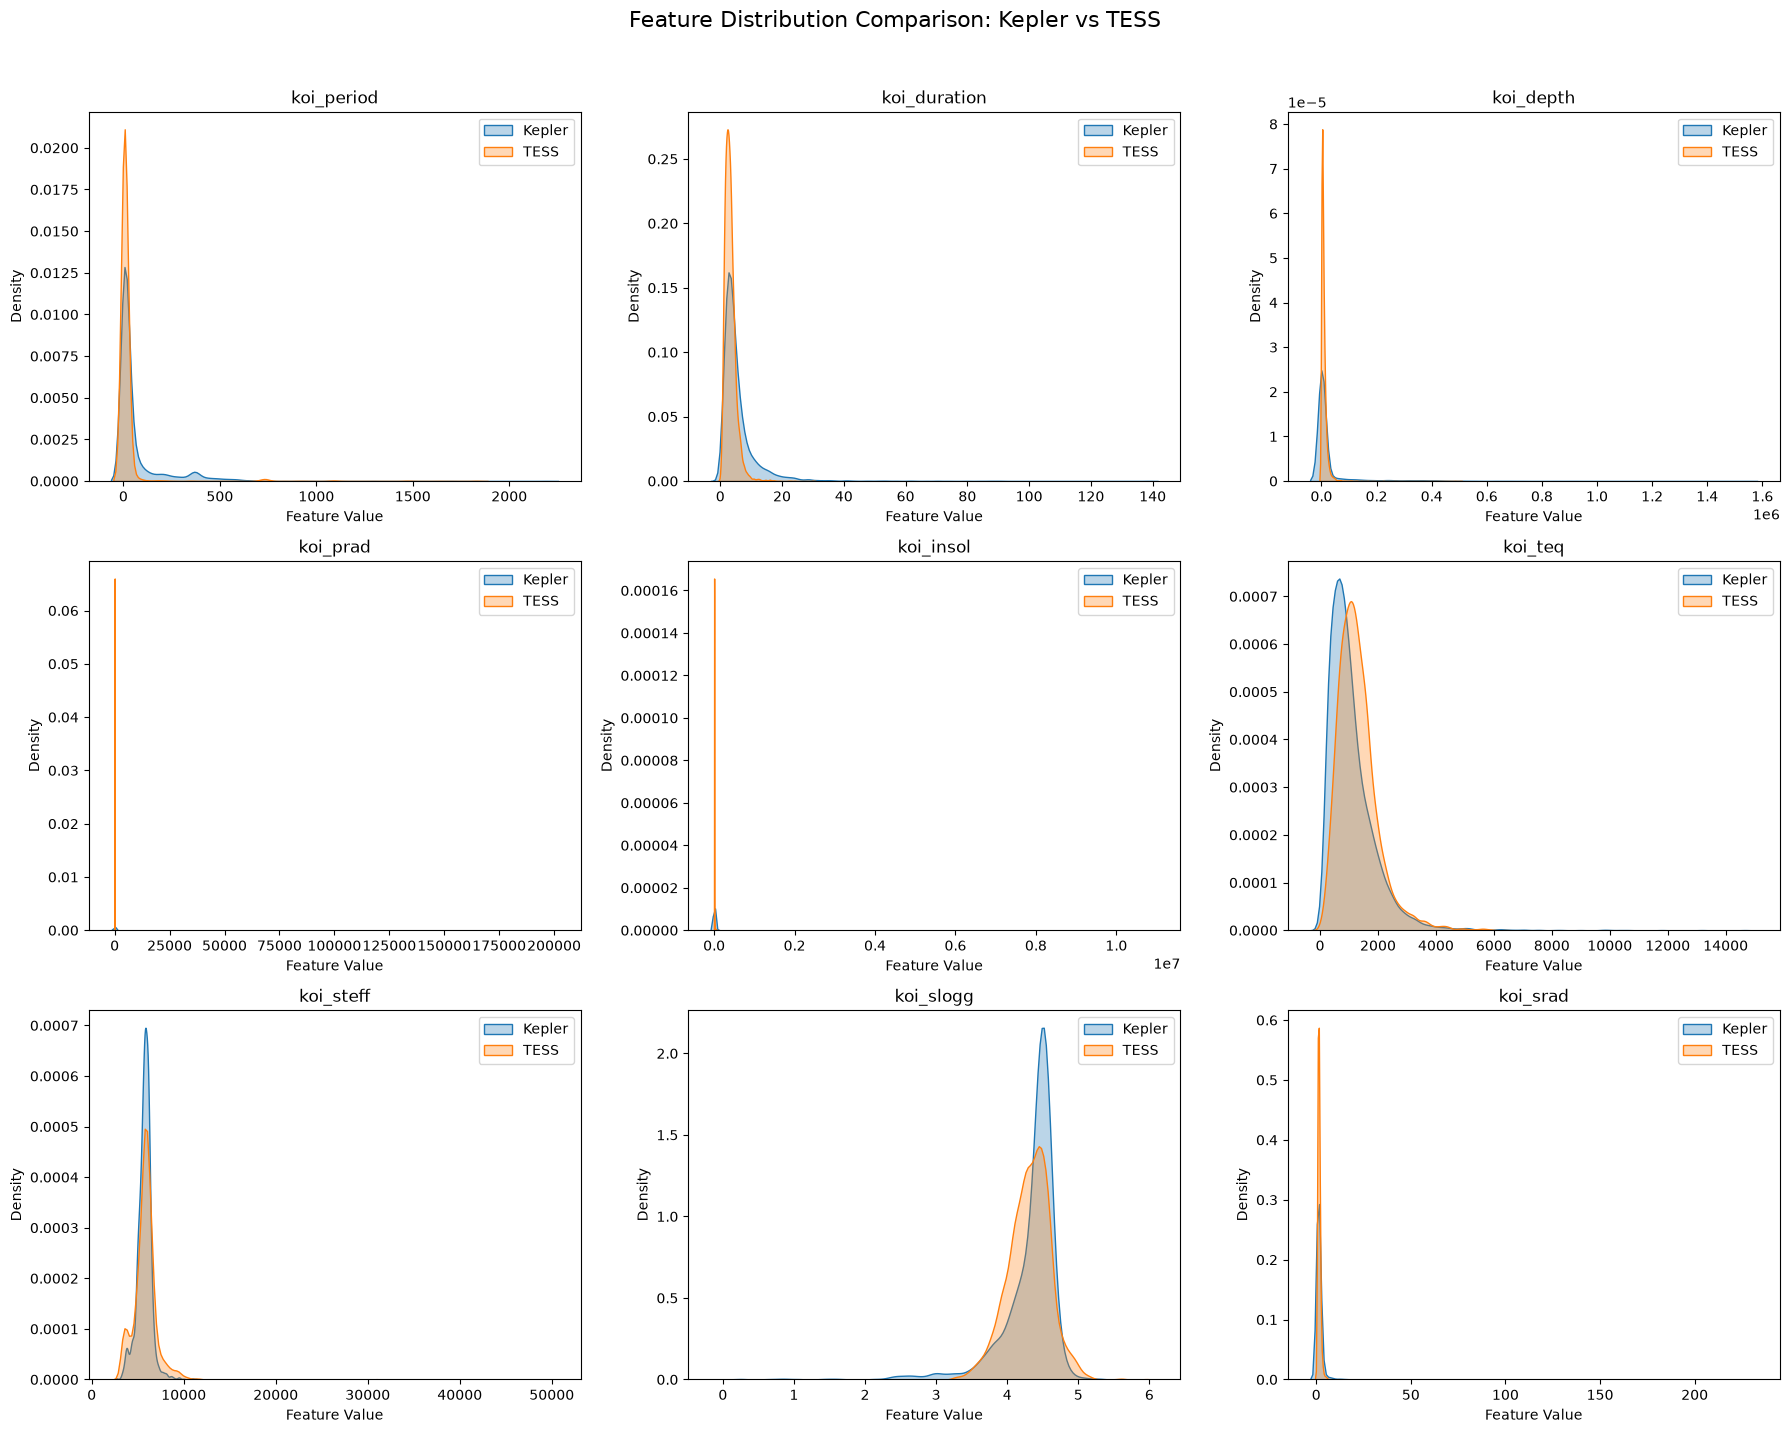

In [18]:
# CELL 15: VISUALIZE KEPLER-TESS DOMAIN SHIFT

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(
    nrows=3,
    ncols=3,
    figsize=(18, 14)
)

axes = axes.flatten()

for i, feature in enumerate(shared_features):

    sns.kdeplot(
        data=X_shared_train,
        x=feature,
        label="Kepler",
        fill=True,
        alpha=0.3,
        ax=axes[i]
    )

    sns.kdeplot(
        data=X_tess_external,
        x=feature,
        label="TESS",
        fill=True,
        alpha=0.3,
        ax=axes[i]
    )

    axes[i].set_title(feature)
    axes[i].set_xlabel("Feature Value")
    axes[i].set_ylabel("Density")
    axes[i].legend()

plt.suptitle(
    "Feature Distribution Comparison: Kepler vs TESS",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()

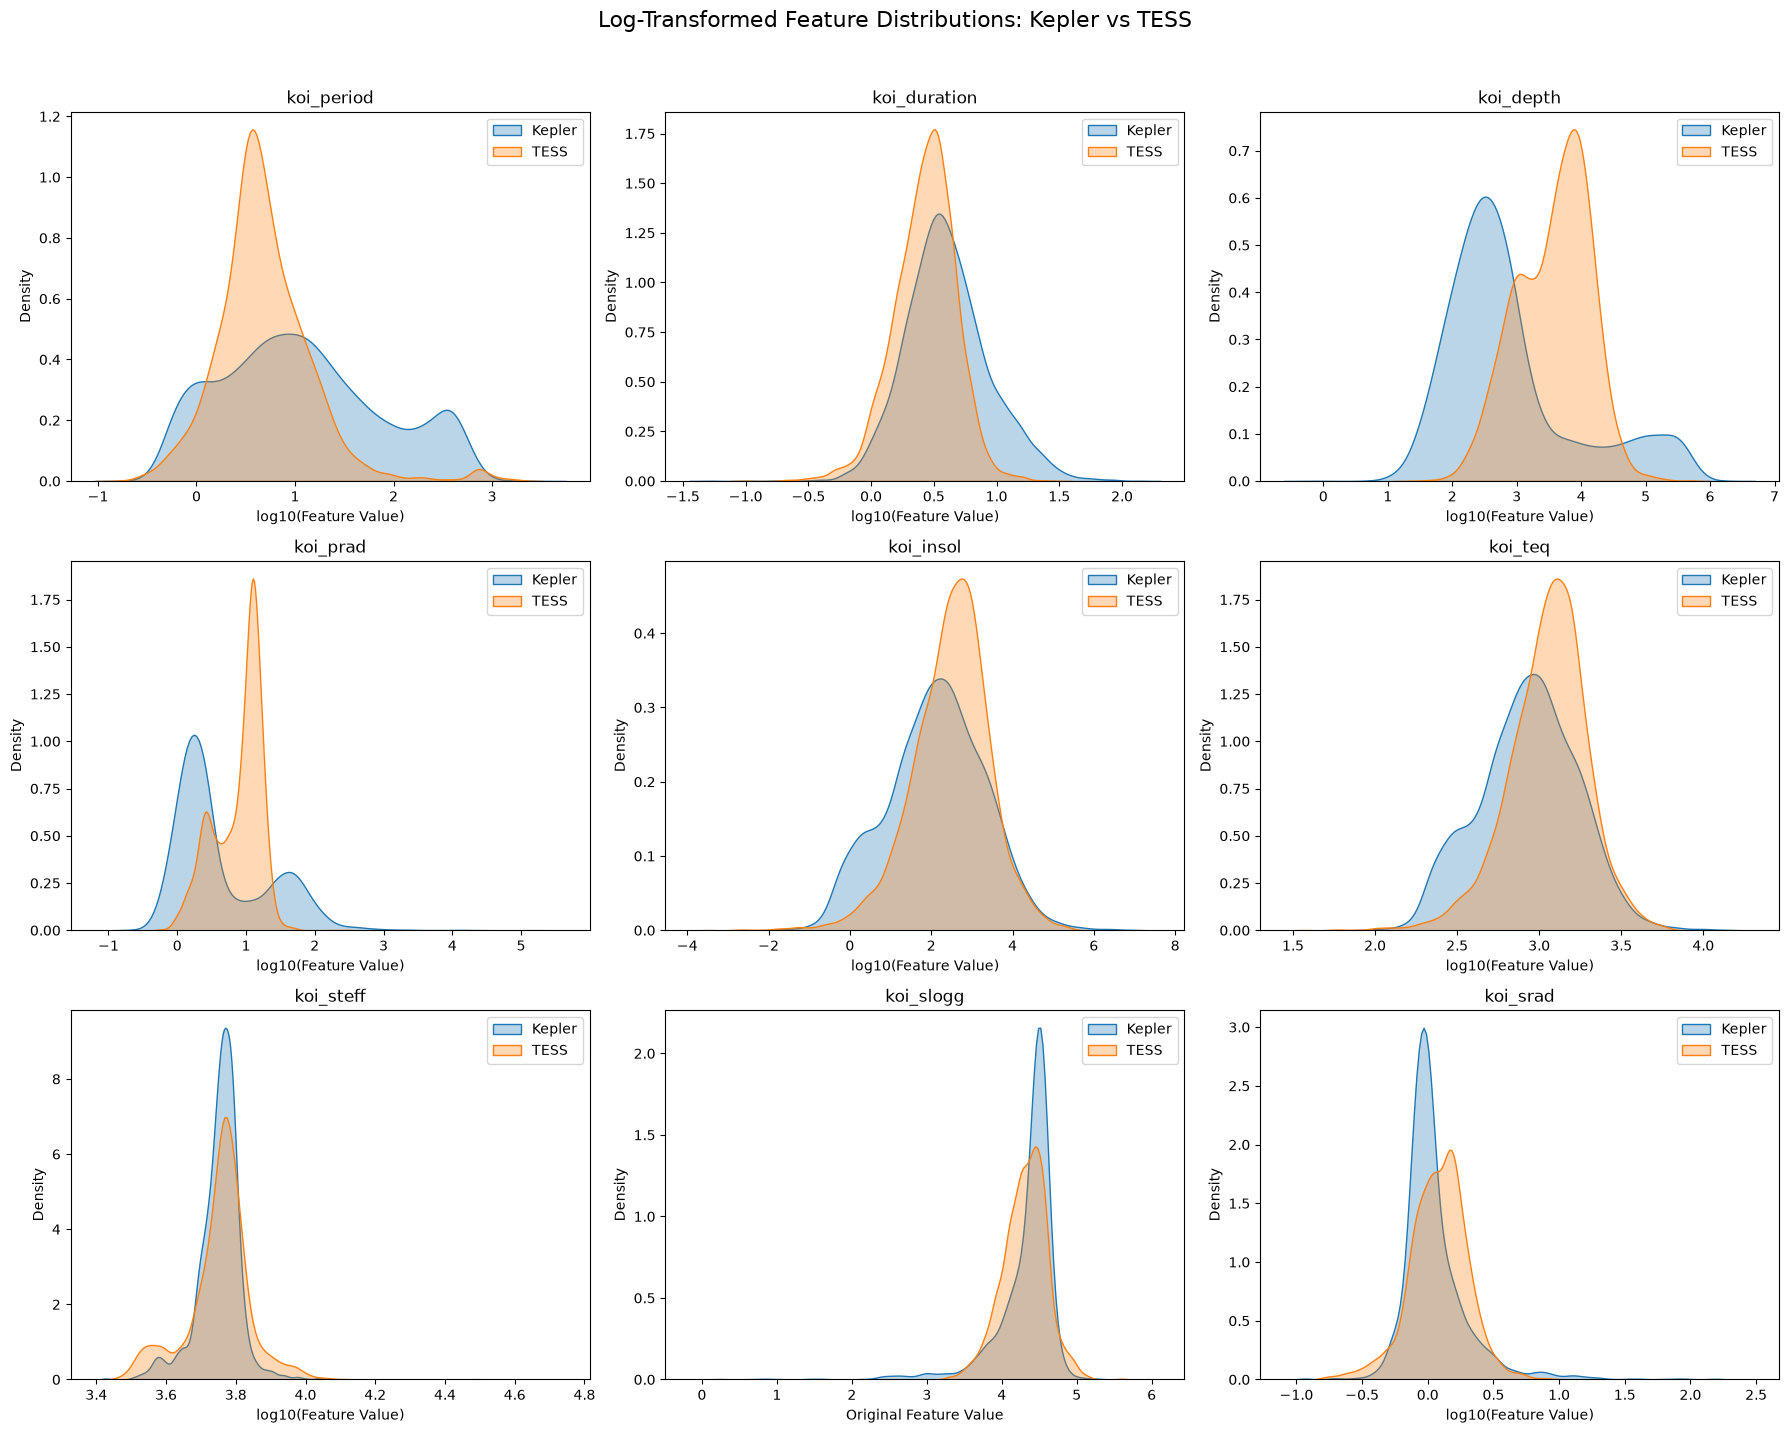

In [19]:
# CELL 16: IMPROVED DISTRIBUTION VISUALIZATION

fig, axes = plt.subplots(
    nrows=3,
    ncols=3,
    figsize=(18, 14)
)

axes = axes.flatten()

for i, feature in enumerate(shared_features):

    kepler_values = X_shared_train[feature].dropna()
    tess_values = X_tess_external[feature].dropna()

    # Log transformation for visualization only
    if feature != "koi_slogg":

        kepler_values = np.log10(
            kepler_values[kepler_values > 0]
        )

        tess_values = np.log10(
            tess_values[tess_values > 0]
        )

        x_label = "log10(Feature Value)"

    else:
        x_label = "Original Feature Value"

    sns.kdeplot(
        x=kepler_values,
        label="Kepler",
        fill=True,
        alpha=0.3,
        ax=axes[i]
    )

    sns.kdeplot(
        x=tess_values,
        label="TESS",
        fill=True,
        alpha=0.3,
        ax=axes[i]
    )

    axes[i].set_title(feature)
    axes[i].set_xlabel(x_label)
    axes[i].set_ylabel("Density")
    axes[i].legend()

plt.suptitle(
    "Log-Transformed Feature Distributions: Kepler vs TESS",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()

In [20]:
# CELL 17: FINAL DOMAIN SHIFT SUMMARY

from scipy.stats import ks_2samp

summary_rows = []

for feature in shared_features:

    kepler_values = X_shared_train[feature].dropna()
    tess_values = X_tess_external[feature].dropna()

    ks_statistic, p_value = ks_2samp(
        kepler_values,
        tess_values
    )

    summary_rows.append({

        "Feature": feature,

        "Kepler Median": kepler_values.median(),
        "TESS Median": tess_values.median(),

        "Kepler IQR": (
            kepler_values.quantile(0.75)
            - kepler_values.quantile(0.25)
        ),

        "TESS IQR": (
            tess_values.quantile(0.75)
            - tess_values.quantile(0.25)
        ),

        "KS Statistic": ks_statistic,

        "KS p-value": p_value,

        "Kepler Missing (%)": (
            X_shared_train[feature].isna().mean() * 100
        ),

        "TESS Missing (%)": (
            X_tess_external[feature].isna().mean() * 100
        )
    })


domain_shift_summary = pd.DataFrame(
    summary_rows
).sort_values(
    by="KS Statistic",
    ascending=False
).reset_index(drop=True)


print("FINAL DOMAIN SHIFT SUMMARY")
print("=" * 100)

display(
    domain_shift_summary.round(4)
)

FINAL DOMAIN SHIFT SUMMARY


,Feature,Kepler Median,TESS Median,Kepler IQR,TESS IQR,KS Statistic,KS p-value,Kepler Missing (%),TESS Missing (%)
0,koi_depth,418.3000,4418.0000,1263.0000,8351.8860,0.5142,0.0,3.7516,0.0000
1,koi_prad,2.3700,10.0722,12.8300,9.4333,0.4228,0.0,3.7516,6.7413
2,koi_period,9.9183,4.2608,38.0711,5.8200,0.2956,0.0,0.0000,1.3339
3,koi_duration,3.7921,2.7905,3.8472,2.0016,0.2442,0.0,0.0000,0.0574
4,koi_srad,0.9970,1.2400,0.5040,0.7853,0.2269,0.0,3.7516,8.2903
5,koi_teq,873.0000,1179.0000,835.5000,795.8593,0.2166,0.0,3.7516,3.7866
6,koi_slogg,4.4400,4.3300,0.3225,0.3861,0.1886,0.0,3.7516,11.4601
7,koi_insol,138.5100,353.8941,824.1100,1106.7403,0.1798,0.0,3.3072,2.4527
8,koi_steff,5765.0000,5801.2000,799.5000,1106.9100,0.1064,0.0,3.7516,2.3379


In [21]:
# CELL 18: SAVE TESS VALIDATION ARTIFACTS

import json
import joblib
from pathlib import Path
from sklearn.metrics import classification_report

# Create directories
models_dir = project_root / "models"
processed_dir = project_root / "data" / "processed"

models_dir.mkdir(parents=True, exist_ok=True)
processed_dir.mkdir(parents=True, exist_ok=True)


# --------------------------------------------------
# 1. SAVE REDUCED-FEATURE CATBOOST MODEL
# --------------------------------------------------

tess_model_artifact = {

    "pipeline": reduced_catboost_pipeline,

    "feature_names": shared_features,

    "feature_mapping": feature_mapping,

    "target_classes": class_order,

    "model_name": "CatBoost",

    "validation_dataset": "Kepler",

    "external_validation_dataset": "TESS",

    "tess_macro_f1": float(tess_macro_f1),

    "tess_accuracy": float(tess_accuracy),

    "tess_balanced_accuracy": float(tess_balanced_accuracy)
}

joblib.dump(
    tess_model_artifact,
    models_dir / "exodetect_catboost_9feature_tess_validation.pkl"
)


# --------------------------------------------------
# 2. SAVE DOMAIN CLASSIFIER
# --------------------------------------------------

joblib.dump(
    domain_classifier,
    models_dir / "exodetect_domain_classifier.pkl"
)


# --------------------------------------------------
# 3. SAVE DOMAIN SHIFT SUMMARY
# --------------------------------------------------

domain_shift_summary.to_csv(
    processed_dir / "domain_shift_summary.csv",
    index=False
)


# --------------------------------------------------
# 4. SAVE TESS PREDICTIONS
# --------------------------------------------------

tess_predictions_df = pd.DataFrame(
    {
        "Actual Class": y_tess_external,
        "Predicted Class": y_tess_pred
    },
    index=y_tess_external.index
)

for class_name in class_order:

    tess_predictions_df[
        f"Probability_{class_name}"
    ] = probability_df[class_name]


tess_predictions_df.to_csv(
    processed_dir / "tess_external_predictions.csv",
    index=True
)


# --------------------------------------------------
# 5. SAVE VALIDATION METRICS
# --------------------------------------------------

tess_report = classification_report(
    y_tess_external,
    y_tess_pred,
    labels=class_order,
    output_dict=True,
    zero_division=0
)

validation_results = {

    "model": "Reduced Feature CatBoost",

    "features_used": shared_features,

    "feature_mapping": feature_mapping,

    "training_dataset": "Kepler",

    "external_validation_dataset": "TESS",

    "training_samples": int(len(X_shared_train)),

    "kepler_test_samples": int(len(X_shared_test)),

    "tess_validation_samples": int(len(X_tess_external)),

    "excluded_tess_samples": int(
        len(tess) - len(X_tess_external)
    ),

    "metrics": {

        "accuracy": float(tess_accuracy),

        "balanced_accuracy": float(tess_balanced_accuracy),

        "macro_f1": float(tess_macro_f1)
    },

    "classification_report": tess_report,

    "confusion_matrix": cm_tess.tolist(),

    "class_order": class_order,

    "domain_classifier": {

        "accuracy": float(
            accuracy_score(y_domain_test, domain_predictions)
        ),

        "roc_auc": float(
            roc_auc_score(y_domain_test, domain_probabilities)
        )
    }
}


with open(
    models_dir / "tess_validation_results.json",
    "w"
) as file:

    json.dump(
        validation_results,
        file,
        indent=4
    )


# --------------------------------------------------
# 6. CONFIRM SAVED FILES
# --------------------------------------------------

print("TESS VALIDATION ARTIFACTS SAVED")
print("=" * 65)

saved_files = [

    models_dir / "exodetect_catboost_9feature_tess_validation.pkl",

    models_dir / "exodetect_domain_classifier.pkl",

    models_dir / "tess_validation_results.json",

    processed_dir / "domain_shift_summary.csv",

    processed_dir / "tess_external_predictions.csv"
]

for file_path in saved_files:

    print(
        f"{file_path.relative_to(project_root)} : "
        f"{'EXISTS' if file_path.exists() else 'MISSING'}"
    )

TESS VALIDATION ARTIFACTS SAVED
models\exodetect_catboost_9feature_tess_validation.pkl : EXISTS
models\exodetect_domain_classifier.pkl : EXISTS
models\tess_validation_results.json : EXISTS
data\processed\domain_shift_summary.csv : EXISTS
data\processed\tess_external_predictions.csv : EXISTS


In [22]:
# CELL 19: VERIFY SAVED TESS VALIDATION ARTIFACTS

import joblib
import json
import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. LOAD SAVED CATBOOST MODEL
# --------------------------------------------------

loaded_tess_artifact = joblib.load(
    models_dir / "exodetect_catboost_9feature_tess_validation.pkl"
)

loaded_tess_model = loaded_tess_artifact["pipeline"]

print("CATBOOST MODEL")
print("=" * 60)

print("Model:", loaded_tess_artifact["model_name"])
print("Features:", len(loaded_tess_artifact["feature_names"]))


# --------------------------------------------------
# 2. VERIFY FEATURE COMPATIBILITY
# --------------------------------------------------

assert (
    loaded_tess_artifact["feature_names"]
    == shared_features
)

print("\nFeature compatibility: VERIFIED")


# --------------------------------------------------
# 3. REGENERATE TESS PREDICTIONS
# --------------------------------------------------

reloaded_predictions = loaded_tess_model.predict(
    X_tess_external
).ravel()

reloaded_probabilities = loaded_tess_model.predict_proba(
    X_tess_external
)

assert np.array_equal(
    reloaded_predictions,
    y_tess_pred
)

assert np.allclose(
    reloaded_probabilities,
    tess_probabilities
)

print("Prediction consistency: VERIFIED")
print("Probability consistency: VERIFIED")


# --------------------------------------------------
# 4. VERIFY DOMAIN CLASSIFIER
# --------------------------------------------------

loaded_domain_classifier = joblib.load(
    models_dir / "exodetect_domain_classifier.pkl"
)

print("\nDOMAIN CLASSIFIER")
print("=" * 60)

print("Domain classifier loaded successfully.")


# --------------------------------------------------
# 5. VERIFY JSON RESULTS
# --------------------------------------------------

with open(
    models_dir / "tess_validation_results.json",
    "r"
) as file:

    loaded_results = json.load(file)

print("\nVALIDATION METRICS")
print("=" * 60)

print(
    "Accuracy:",
    loaded_results["metrics"]["accuracy"]
)

print(
    "Balanced Accuracy:",
    loaded_results["metrics"]["balanced_accuracy"]
)

print(
    "Macro F1:",
    loaded_results["metrics"]["macro_f1"]
)


# --------------------------------------------------
# 6. VERIFY CSV FILES
# --------------------------------------------------

loaded_predictions_df = pd.read_csv(
    processed_dir / "tess_external_predictions.csv"
)

loaded_domain_summary = pd.read_csv(
    processed_dir / "domain_shift_summary.csv"
)

print("\nCSV VERIFICATION")
print("=" * 60)

print(
    "TESS predictions shape:",
    loaded_predictions_df.shape
)

print(
    "Domain shift summary shape:",
    loaded_domain_summary.shape
)


# --------------------------------------------------
# FINAL STATUS
# --------------------------------------------------

print("\n" + "=" * 60)
print("ALL ARTIFACT VERIFICATION CHECKS PASSED")
print("=" * 60)

CATBOOST MODEL
Model: CatBoost
Features: 9

Feature compatibility: VERIFIED
Prediction consistency: VERIFIED
Probability consistency: VERIFIED

DOMAIN CLASSIFIER
Domain classifier loaded successfully.

VALIDATION METRICS
Accuracy: 0.28284566838783703
Balanced Accuracy: 0.5187423868993369
Macro F1: 0.29306552363283167

CSV VERIFICATION
TESS predictions shape: (6972, 6)
Domain shift summary shape: (9, 9)

ALL ARTIFACT VERIFICATION CHECKS PASSED


# 06 — TESS Cross-Mission Validation

## 1. Objective

The objective of this notebook was to evaluate whether the machine learning model trained using NASA Kepler catalogue data could generalize to NASA TESS catalogue data.

Since the original Kepler model used 31 features, but the TESS dataset did not contain all those features, a separate nine-feature model was developed using physically corresponding catalogue parameters available in both datasets.

## 2. Feature Mapping

Nine shared catalogue features were selected:

- Orbital period
- Transit duration
- Transit depth
- Planet radius
- Insolation flux
- Equilibrium temperature
- Stellar effective temperature
- Stellar surface gravity
- Stellar radius

The transit epoch feature was excluded because the two missions use different reference epochs.

## 3. Kepler Benchmark

A reduced-feature CatBoost model was trained using the Kepler training partition.

Its performance on the Kepler test partition was:

- Accuracy: 74.92%
- Balanced Accuracy: 69.23%
- Macro F1-score: 69.01%

The reduced-feature model performed below the original 31-feature model, which achieved a Macro F1-score of approximately 75.27%.

## 4. TESS External Validation

The trained Kepler model was evaluated directly on the selected TESS observations without retraining or tuning on TESS.

TESS target mappings:

- PC → CANDIDATE
- CP → CONFIRMED
- FP → FALSE POSITIVE

Other TESS dispositions were excluded from this three-class experiment.

External validation results:

- Accuracy: 28.28%
- Balanced Accuracy: 51.87%
- Macro F1-score: 29.31%

The significant performance reduction indicates poor cross-mission generalization.

## 5. Domain-Shift Investigation

Three diagnostic approaches were used:

**Kolmogorov-Smirnov tests**

All nine shared features showed statistically significant distribution differences between Kepler and TESS.

The largest KS statistics were observed for:

- Transit depth: 0.5142
- Planet radius: 0.4228
- Orbital period: 0.2956

**Domain classifier**

A separate Random Forest classifier was trained to distinguish Kepler observations from TESS observations.

Results:

- Accuracy: 90.43%
- ROC-AUC: 96.47%

This indicates that the two mission datasets are highly distinguishable using the selected features.

**Distribution visualizations**

Original and logarithmically transformed feature distributions were compared. These visualizations further demonstrated differences in the feature distributions between the missions.

## 6. Final Conclusion

The experiment demonstrates that a model trained on Kepler catalogue data does not necessarily generalize well to TESS catalogue data, even when both datasets contain corresponding physical parameters.

The strong domain-classification performance and differences in feature distributions provide evidence of substantial cross-mission domain shift.

Potential contributing factors include:

- Differences in observed planetary populations.
- Mission-specific selection effects.
- Differences in catalogue measurement and processing procedures.
- Differences in missing-value patterns.
- Differences in target disposition definitions and class distributions.

These are potential explanations rather than individually proven causes.

## 7. Limitations

1. The experiment uses catalogue parameters rather than raw transit light curves.
2. Kepler and TESS disposition categories are not perfectly equivalent.
3. Only nine shared features were used for external validation.
4. The selected TESS sample excludes known planets, ambiguous candidates, false alarms, and missing dispositions.
5. The domain classifier identifies dataset separability but does not establish the exact cause of the ExoDetect performance reduction.
6. No domain adaptation or TESS-based model retraining was performed.

## 8. Artifacts Saved

The following artifacts were saved:

- Reduced-feature CatBoost model.
- Domain classifier.
- TESS validation metrics.
- TESS prediction probabilities.
- Domain-shift summary.

All saved artifacts were successfully reloaded and verified. Predictions and probabilities from the reloaded CatBoost model matched the original results.

**Notebook 06 completed successfully.**